# ML-06 — Signal Audit: Do the Flags Hold?

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [ ]:
# --- setup: clone repo in Colab, put work/src on the path, build (or load cached) cutoff frames ---
import os, sys, json, datetime as dt
REPO_DIR = "/content/FlyRank-ML-Internship"
if os.path.isdir("/content") and not os.environ.get("CAPSTONE_LOCAL"):
    if not os.path.isdir(REPO_DIR):
        os.system(f"git clone https://github.com/joannadulay/FlyRank-ML-Internship.git {REPO_DIR}")
    os.chdir(REPO_DIR)
    os.system("pip install -q datasets duckdb scikit-learn huggingface_hub pyarrow")
sys.path.insert(0, "work/src")
import numpy as np, pandas as pd
import capstone_lib as L
os.makedirs(L.OUT_DIR, exist_ok=True)
plan, frames, TOKEN, LOCAL = L.start()
train, val = frames["train"], frames["val"]          # the sealed test frame is not touched in this notebook
print("cutoffs  train:", [str(t) for t in plan["train"]], "| val:", plan["val"])
print("rows     train:", len(train), "| val:", len(val))

cutoffs  train: ['2026-01-11', '2026-02-08', '2026-03-08', '2026-04-05'] | val: 2026-05-03
rows     train: 237571 | val: 85997


## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

           count    mean      std    min     50%      90%      99%        max  \
rate_B  237571.0  94.847  229.170  3.571  29.679  220.214  953.475  24201.893   
d_impr  237571.0   0.173    0.599 -7.592   0.177    0.839    1.741      7.779   
ctr_B   237571.0   0.003    0.004  0.000   0.001    0.007    0.017      0.274   
pos_B   237571.0  12.143   12.652  0.000   7.436   28.328   64.087    112.149   
cv_B    237571.0   0.508    0.289  0.056   0.450    0.804    1.601      5.087   

          skew  
rate_B  14.639  
d_impr  -0.358  
ctr_B    8.020  
pos_B    2.325  
cv_B     3.249  

max / median of rate_B: 815
share of rows with gsc position exactly 0: 0.0

Label shares (train):
y
Stable      0.367
Growth      0.293
Decline     0.283
Recovery    0.057
Name: proportion, dtype: float64


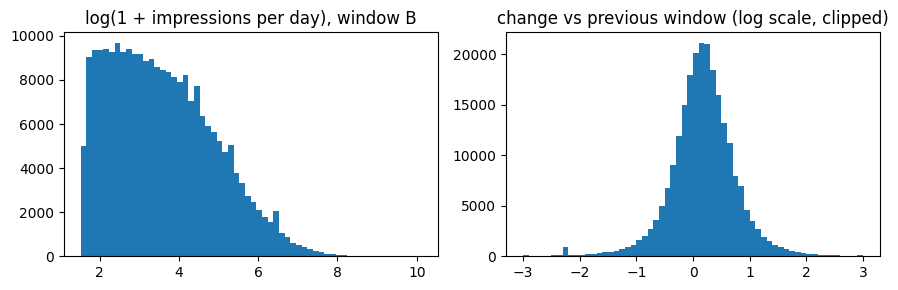

In [ ]:
cols = ["rate_B", "d_impr", "ctr_B", "pos_B", "cv_B"]
desc = train[cols].describe(percentiles=[.5, .9, .99]).T
desc["skew"] = train[cols].skew()
print(desc.round(3))
print()
print("max / median of rate_B:", round(train.rate_B.max() / train.rate_B.median()))
print("share of rows with gsc position exactly 0:", round((train.pos_B == 0).mean(), 4))
print()
print("Label shares (train):")
print(train.y.value_counts(normalize=True).round(3))
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(train.log_rate_B, bins=60); ax[0].set_title("log(1 + impressions per day), window B")
ax[1].hist(train.d_impr.clip(-3, 3), bins=60); ax[1].set_title("change vs previous window (log scale, clipped)")
plt.tight_layout(); plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [ ]:
pool = pd.concat([train, val], ignore_index=True)          # development data only
pool["is_decline"] = (pool.y == "Decline").astype(int)
pool["is_stable"] = (pool.y == "Stable").astype(int)
pool["is_upside"] = pool.y.isin(["Growth", "Recovery"]).astype(int)

tests = [
    ("S1 momentum: pages already falling keep falling", "d_impr", "is_decline", "down"),
    ("S2 volume: bigger pages are steadier", "log_rate_B", "is_stable", "up"),
    ("S3 position: pages ranking lower have more upside", "pos_B", "is_upside", "up"),
]
verdicts = {}
for name, col, target, expect in tests:
    t = L.bucket_table(pool, col, target)
    v = L.auto_verdict(t, expect)
    per_cut = [L.auto_verdict(L.bucket_table(g, col, target), expect) for _, g in pool.groupby("cutoff")]
    verdicts[name] = dict(verdict=v, per_cutoff=per_cut, buckets=t["rate"].tolist(), n=t["n"].tolist())
    print(name, "| expect rate to go", expect, "as", col, "rises")
    print(t.to_string()); print("  verdict:", v, "| same test at each cutoff:", per_cut, "\n")

S1 momentum: pages already falling keep falling | expect rate to go down as d_impr rises
                     n    rate
d_impr                        
(-7.593, -0.24]  80892  0.4446
(-0.24, 0.099]   80893  0.3223
(0.099, 0.431]   80891  0.2744
(0.431, 7.779]   80892  0.3110
  verdict: MIXED | same test at each cutoff: ['MIXED', 'MIXED', 'OPPOSITE', 'MIXED', 'MIXED'] 

S2 volume: bigger pages are steadier | expect rate to go up as log_rate_B rises
                                 n    rate
log_rate_B                                
(1.5190000000000001, 2.476]  80961  0.3415
(2.476, 3.405]               80860  0.3289
(3.405, 4.475]               80882  0.3554
(4.475, 10.121]              80865  0.4398
  verdict: MIXED | same test at each cutoff: ['CONFIRMED', 'MIXED', 'CONFIRMED', 'MIXED', 'MIXED'] 

S3 position: pages ranking lower have more upside | expect rate to go up as pos_B rises
                       n    rate
pos_B                           
(-0.001, 4.792]    80892  0.2745
(4.

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [ ]:
thr = L.CFG["change_thr"]
rows = []
for c, gg in pool.groupby("cutoff"):
    fell = gg[gg.r_prev <= -thr]
    b = (gg.y == "Decline").mean(); p = (fell.y == "Decline").mean()
    rows.append(dict(cutoff=str(c.date()), base=b, p_decline_given_fell=p, lift=p / b, n_fell=len(fell)))
flag_tab = pd.DataFrame(rows)
print(flag_tab.round(3).to_string(index=False))
n = len(flag_tab)
flag_verdict = ("CONFIRMED" if (flag_tab.lift > 1.2).sum() >= n - 1 else
                "OPPOSITE" if (flag_tab.lift < 0.8).sum() >= n - 1 else "MIXED")
print(f"\nlift by cutoff: {flag_tab.lift.round(2).tolist()} -> {flag_verdict}")

    cutoff  base  p_decline_given_fell  lift  n_fell
2026-01-11 0.155                 0.234 1.508    9144
2026-02-08 0.147                 0.152 1.035    5791
2026-03-08 0.259                 0.244 0.940    7350
2026-04-05 0.473                 0.499 1.053   18083
2026-05-03 0.490                 0.572 1.167   34515

lift by cutoff: [1.51, 1.03, 0.94, 1.05, 1.17] -> MIXED


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

The three simple signals gave mixed results across five months, and pages that had just fallen were only slightly more likely to fall again (lift between 0.9× and 1.5× inside each month). Most of the larger pooled effect came from a decline wave in April and May. So "it fell last month" is a weak reason by itself to prioritise a page. These are observed, directional patterns, not causal claims.

In [ ]:
for name, v in verdicts.items():
    print(f"- {name}: {v['verdict']} (by cutoff: {v['per_cutoff']})")
print(f"- Flag assumption 'falling pages keep falling': {flag_verdict} (lift by cutoff {flag_tab.lift.round(2).tolist()}; directional, not causal).")
json.dump(dict(signals=verdicts, flag_test=dict(by_cutoff=flag_tab.round(4).to_dict("list"), verdict=flag_verdict)),
          open("work/outputs/w04_signal_audit.json", "w"), indent=1)

- S1 momentum: pages already falling keep falling: MIXED (by cutoff: ['MIXED', 'MIXED', 'OPPOSITE', 'MIXED', 'MIXED'])
- S2 volume: bigger pages are steadier: MIXED (by cutoff: ['CONFIRMED', 'MIXED', 'CONFIRMED', 'MIXED', 'MIXED'])
- S3 position: pages ranking lower have more upside: MIXED (by cutoff: ['MIXED', 'MIXED', 'CONFIRMED', 'MIXED', 'MIXED'])
- Flag assumption 'falling pages keep falling': MIXED (lift by cutoff [1.51, 1.03, 0.94, 1.05, 1.17]; directional, not causal).


In [ ]:
print(pool.groupby("cutoff").y.value_counts(normalize=True).unstack().round(3))

spike = pool[(pool.d_impr > -2.5) & (pool.d_impr < -2.0)]
print(len(spike), "pages from", spike.client.nunique(), "clients; by cutoff:", spike.cutoff.value_counts().to_dict())
print(spike.client.value_counts(normalize=True).head(3).round(2))

y           Decline  Growth  Recovery  Stable
cutoff                                       
2026-01-11    0.155   0.448     0.100   0.297
2026-02-08    0.147   0.422     0.059   0.372
2026-03-08    0.259   0.257     0.044   0.439
2026-04-05    0.473   0.138     0.039   0.349
2026-05-03    0.490   0.097     0.048   0.365
1716 pages from 22 clients; by cutoff: {Timestamp('2026-02-08 00:00:00'): 887, Timestamp('2026-01-11 00:00:00'): 363, Timestamp('2026-05-03 00:00:00'): 296, Timestamp('2026-04-05 00:00:00'): 99, Timestamp('2026-03-08 00:00:00'): 71}
client
client_08a6a72ff48e62c0    0.49
client_9958f0a7ae1df715    0.17
client_23a62021009f63c4    0.09
Name: proportion, dtype: float64


In [ ]:
g = pool.groupby(["cutoff", "client"]).agg(n=("y", "size"), dec=("y", lambda s: (s == "Decline").mean())).reset_index()
print(g.groupby("cutoff").agg(clients=("client", "nunique"), median_client_decline=("dec", "median"),
      share_clients_majority_decline=("dec", lambda s: (s > 0.5).mean())).round(3))
print("\nshare of all rows by the top clients:\n", pool.client.value_counts(normalize=True).head(5).round(3))

top = spike.client.value_counts().index[0]
print("\nlabels for the spike's biggest client:\n", pool[(pool.client == top) & (pool.d_impr < -2.0)].y.value_counts(normalize=True).round(2))

rows = []
for c, gg in pool.groupby("cutoff"):
    fell = gg[gg.r_prev <= -thr]
    rows.append(dict(cutoff=c.date(), base=(gg.y == "Decline").mean(), p_dec_given_fell=(fell.y == "Decline").mean(), n_fell=len(fell)))
t = pd.DataFrame(rows); t["lift"] = t.p_dec_given_fell / t.base
print("\nflag test inside each cutoff:\n", t.round(3).to_string(index=False))

            clients  median_client_decline  share_clients_majority_decline
cutoff                                                                    
2026-01-11       25                  0.137                           0.160
2026-02-08       26                  0.233                           0.077
2026-03-08       26                  0.255                           0.077
2026-04-05       36                  0.419                           0.389
2026-05-03       38                  0.465                           0.368

share of all rows by the top clients:
 client
client_73cda7b4e4f265ea    0.258
client_62f4a7e64f5e0096    0.195
client_23a62021009f63c4    0.137
client_e547b89c05043229    0.125
client_fef1a8f436438636    0.082
Name: proportion, dtype: float64

labels for the spike's biggest client:
 y
Recovery    1.0
Decline     0.0
Name: proportion, dtype: float64

flag test inside each cutoff:
     cutoff  base  p_dec_given_fell  n_fell  lift
2026-01-11 0.155             0.234    914

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.